# Animal Analysis Example
This notebook demonstrates animal-level analysis functions for tracking performance across sessions


In [1]:
from ethopy_analysis.data.loaders import get_sessions, get_mouse_weight
from ethopy_analysis.data.analysis import get_performance, get_no_repeat_performance, weight_check
from ethopy_analysis.plots.animal import (
    plot_session_performance,
    plot_session_no_repeat_performance,
    plot_performance_liquid,
    plot_session_date,
    plot_trial_per_session,
    plot_animal_weight,
)

# Apply plot styling (optional)
from ethopy_analysis.config.styles import Style
Style().apply()

In [3]:
# Load session data for a specific animal
# get_sessions() retrieves all sessions for an animal
# Parameters: animal_id (int), min_trials (int), from_date (str), to_date (str), format ('df'/'dj')

animal_id = 484
sessions = get_sessions(animal_id, min_trials=20)

# examples
# get_sessions(animal_id, min_trials=20, from_date="2023-01-01", to_date="2023-12-31")
# get_sessions(animal_id, min_trials=20 format="dj") # DataJoint format

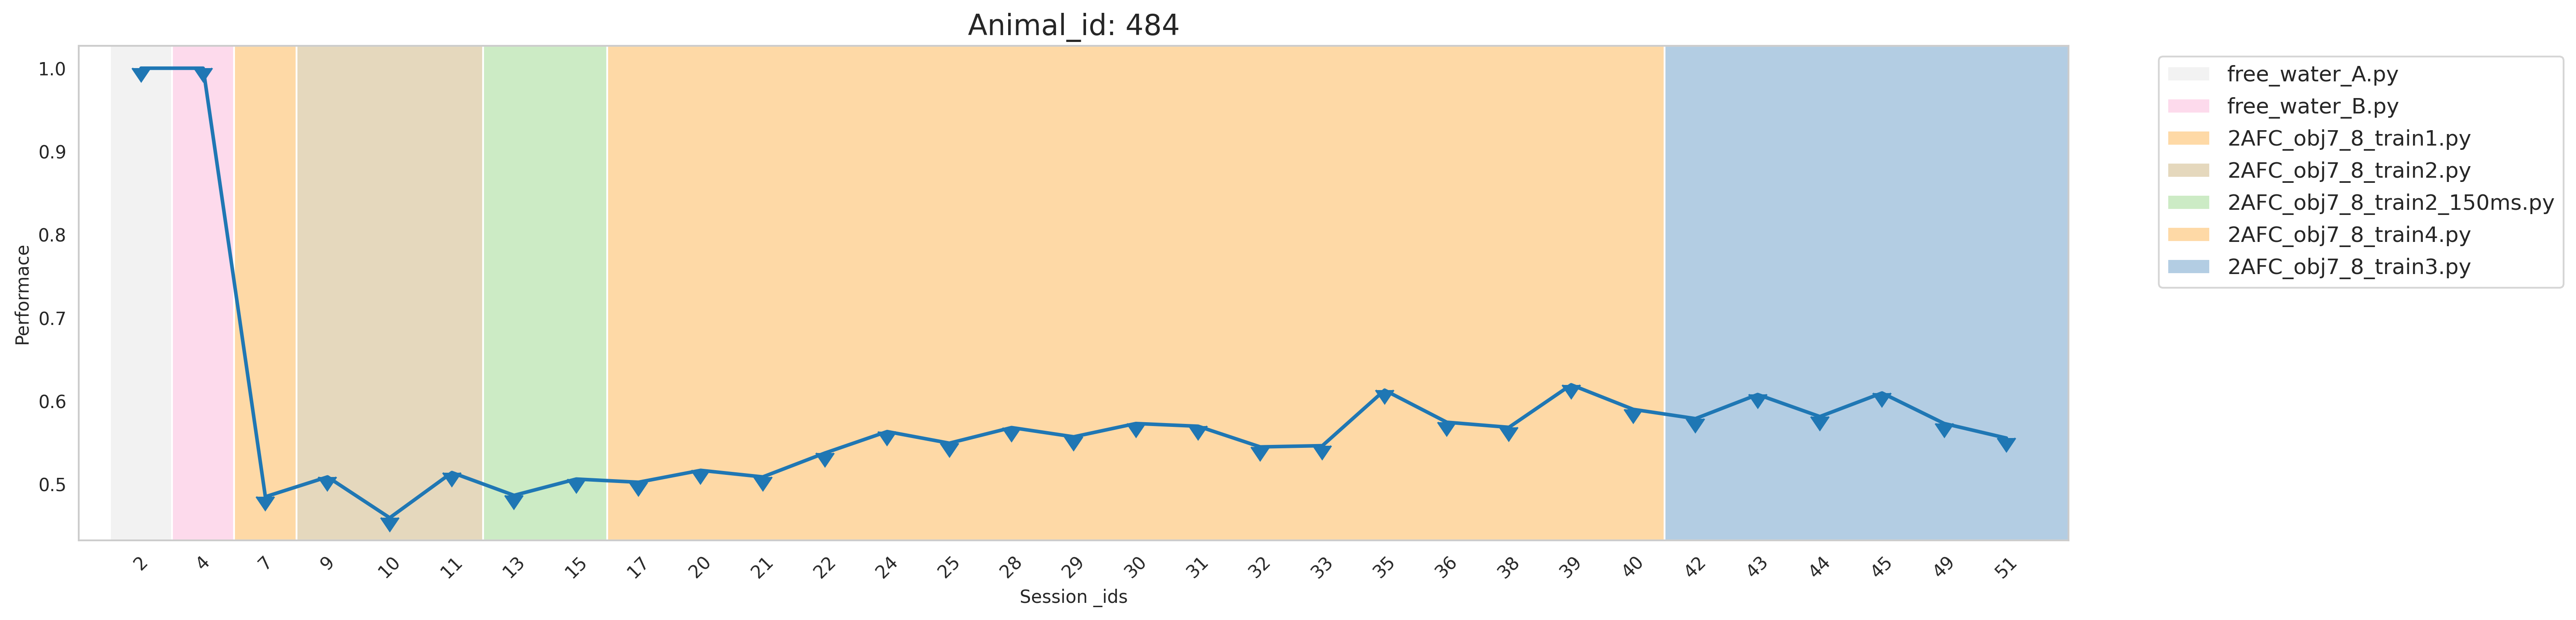

In [4]:
# Plot performance across sessions with protocol name visualization
# plot_session_performance() creates line plot showing performance over time
# Parameters: animal_id (int), sessions (List[int]), perf_func (callable), save_path (str), difficulty (None, 'All', or list)
# Returns: List of performance values for each session

# difficulty options:
#   None   -> one "total" line across sessions, using all trials (ignores difficulty)
#   "All"  -> one colored line per difficulty that exists in the sessions
#   [1, 2] -> one colored line per listed difficulty (sessions without them are skipped)
difficulty = None

perfs = plot_session_performance(animal_id, sessions['session'].values, perf_func=get_performance, difficulty=difficulty)

In [12]:
# Plot performance across sessions without repeated trials
# plot_session_no_repeat_performance() creates line plot of no-repeat performance over time
# Parameters: animal_id (int), sessions (List[int]), perf_func (callable), save_path (str)
# Returns: List of performance values for each session

difficulty = [2]  # define your desired difficulty
perfs_no_repeat = plot_session_no_repeat_performance(
    animal_id, sessions['session'].values, perf_func=lambda a, s: get_no_repeat_performance(a, s, difficulty=difficulty),
    repeat_line=True,
    difficulty=difficulty,
)

TypeError: plot_session_no_repeat_performance() got an unexpected keyword argument 'plot_repeat'

In [ ]:
# Plot performance vs liquid reward consumption
# plot_performance_liquid() creates dual-axis plot showing behavior and reward consumption
# Parameters: animal_id (int), animal_sessions (DataFrame), xaxis ('session'/'date'), save_path (str)

plot_performance_liquid(animal_id, sessions, xaxis='session')  # xaxis = 'date' or 'session'

In [ ]:
# Plot sessions per date to visualize training schedule
# plot_session_date() creates bar chart showing number of sessions per date
# Parameters: animal_id (int), min_trials (int), save_path (str)
# Returns: Dict mapping each date to list of session IDs

session_same_date = plot_session_date(animal_id, min_trials=1)

In [ ]:
# Plot distribution of trials per session
# plot_trial_per_session() creates bar chart showing trial counts per session
# Parameters: animal_id (int), min_trials (int), save_path (str)

plot_trial_per_session(animal_id, min_trials=30)

## Animal weight

Requires the optional `mice` schema in your configuration, e.g. `"mice": "lab_mice"`.

In [ ]:
# Load the weight measurements of an animal, sorted by timestamp
# get_mouse_weight() returns a DataFrame with animal_id, timestamp and weight
# Parameters: animal_id (int), from_date (str), to_date (str), format ('df'/'dj')

weight_df = get_mouse_weight(animal_id)
weight_df.tail()

In [ ]:
# Check the weight against the water deprivation reference weight
# weight_check() warns if the animal is under the limit or has not been weighted lately
# Parameters: animal_id (int), count_from (int), weight_days (int), weight_percentage (float)
# count_from -> index of the measurement used as reference, adjust it to the start of deprivation
# Returns: dict with reference_weight, last_weight, percentage and days_since_last

weight_check(animal_id, count_from=5, weight_days=8, weight_percentage=0.7, weight_df=weight_df)

In [ ]:
# Plot the weight over time with the water deprivation limits
# plot_animal_weight() draws a line per measurement and one line per threshold
# Parameters: weight_df (DataFrame), animal_id (int), count_from (int), thresholds (tuple), save_path (str)

fig, ax = plot_animal_weight(weight_df, animal_id=animal_id, count_from=5)